# BRDF python implementation walkthrough with synthetic data

Implements the recommended production scheme for one wavelength: all sites solved together with the state vector

$$\mathbf{x} = [\alpha_1, \ldots, \alpha_n,\; \beta_1, \ldots, \beta_n,\; \gamma]$$

($2n+1$ elements for $n$ sites). Each site keeps its own baseline $\alpha_x$ and directional sensitivity $\beta_x$ (surfaces differ); one $\gamma$ is shared by every scene at every site. A squared-error function compares model predictions to the full observation sequence, minimized with a generic nonlinear optimizer.

Synthetic setup: 150 scenes split across 3 sites with different surface properties, one common drift ($\gamma_{true} = -0.385$ %/yr), 0.3% noise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 110

## 1. Truth definition and synthetic data creation

This chunk defines the true parameter values (a shared drift rate plus each site's baseline and directional sensitivity) and uses them to generate a synthetic archive of 150 noisy scenes (stacked arrays of site ID, time, cos(SZA), and apparent reflectance).

In [2]:
GAMMA_TRUE = -0.00385          # true shared drift rate, fraction per year

SITE_TRUTH = {                 # site name: (alpha, beta, number of scenes)
    "Libya_4":      (0.442, 0.094, 60),
    "Algeria_3":    (0.380, 0.130, 50),
    "Mauritania_1": (0.520, 0.060, 40),
}
names   = list(SITE_TRUTH)     # site names, in a fixed order
n_sites = len(names)

site_id, t, g, rho = [], [], [], []

for site_name in names:
    alpha_true, beta_true, n_scenes = SITE_TRUTH[site_name]
    this_site_id = names.index(site_name)          # integer code: 0, 1, 2, in name order

    scene_times = rng.uniform(0.0, 3.5, n_scenes)              # acquisition times, years since epoch
    scene_szas  = rng.uniform(15.0, 55.0, n_scenes)            # solar zenith angles, degrees
    scene_g     = np.cos(np.radians(scene_szas))               # geometry regressor, cos(SZA)

    site_factor  = alpha_true + beta_true * scene_g            # surface directional factor per scene
    drift_factor = 1 + GAMMA_TRUE * scene_times                # normalized instrument response per scene
    noise_factor = 1 + 0.003 * rng.standard_normal(n_scenes)   # 0.3% random noise
    scene_rho    = site_factor * drift_factor * noise_factor   # apparent reflectance (the observation)

    site_id += [this_site_id] * n_scenes
    t       += list(scene_times)
    g       += list(scene_g)
    rho     += list(scene_rho)

site_id = np.array(site_id)     # which site each scene belongs to (0/1/2)
t       = np.array(t)           # all scenes' times, all sites stacked
g       = np.array(g)           # all scenes' cos(SZA)
rho     = np.array(rho)         # all scenes' observed reflectance
N       = len(rho)

print(f"{N} scenes total across {n_sites} sites")

## Display synthetic three site archive
Apparent reflectance for all 150 scenes plotted against acquisition time (left) and cos(SZA) (right), colored by site.

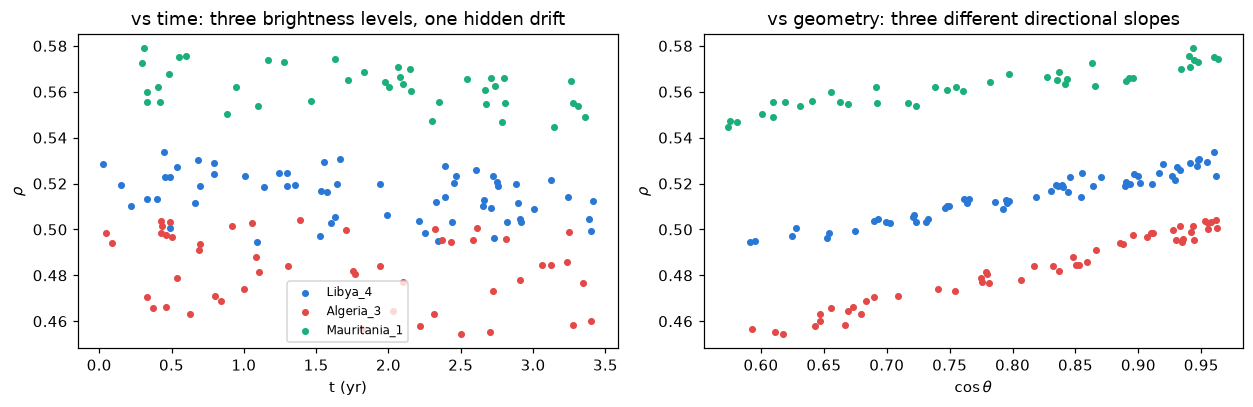

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
site_colors = ['#2a78d6', '#e34948', '#1baf7a']    # one color per site, in name order

for site_name in names:
    this_site_id   = names.index(site_name)         # integer code: 0, 1, 2, in name order
    is_this_site   = site_id == this_site_id        # True/False mask: which rows belong to this site
    this_color     = site_colors[this_site_id]

    axes[0].scatter(t[is_this_site],   rho[is_this_site], s=13, color=this_color, label=site_name)
    axes[1].scatter(g[is_this_site],   rho[is_this_site], s=13, color=this_color)

axes[0].set_xlabel('t (yr)'); axes[0].set_ylabel(r'$\rho$'); axes[0].legend(fontsize=8)
axes[0].set_title('vs time: three brightness levels, one hidden drift')
axes[1].set_xlabel(r'$\cos\theta$'); axes[1].set_ylabel(r'$\rho$')
axes[1].set_title('vs geometry: three different directional slopes')
plt.tight_layout(); plt.show()

## 2. The state vector

The state vector is a flat array holding every unknown for a given wavelength, in a fixed order: the n site alphas first, then the n site betas, then the shared gamma last (7 elements total in this case where n = 3). 

In [4]:
def unpack(x):
    """x = [alpha_1..alpha_n, beta_1..beta_n, gamma]"""
    return x[:n_sites], x[n_sites:2*n_sites], x[2*n_sites]

labels = [f"alpha_{nm}" for nm in names] + [f"beta_{nm}" for nm in names] + ["gamma"]
x_true = np.array([SITE_TRUTH[nm][0] for nm in names]
                + [SITE_TRUTH[nm][1] for nm in names] + [GAMMA_TRUE])

print(f"state vector true values: {2*n_sites + 1} elements\n")
for lab, v in zip(labels, x_true):
    print(f"  {lab:<22} {v:+.5f}")

## 3. Prediction and squared error

The model evaluated at any candidate state vector, and the single number scoring it against all 150 observations.

In [5]:
# Evaluates the model for all scenes (in this case 150) at once, returns array of 150 predicted rho values
def predict(x):
    al, be, ga = unpack(x)
    return (al[site_id] + be[site_id]*g) * (1 + ga*t)

# Scores candidate model using SSE
def sse(x):
    r = predict(x) - rho
    return r @ r # dot product of r

print(f"SSE at truth        : {sse(x_true):.6f}   (noise floor)")
print(f"SSE at truth, no drift (gamma=0): {sse(np.r_[x_true[:-1], 0.0]):.6f}")
print(f"SSE all-zeros       : {sse(np.zeros(2*n_sites+1)):.2f}")

## 4. Starting point

initial guess for optimizer. Per-site bivariate OLS (reflectance vs $\cos\theta$, ignoring time) gives good starts; $\gamma_0 = 0$.This is what was shown on last weeks plots

In [6]:
x0 = np.zeros(2*n_sites + 1)
for k in range(n_sites):
    m = site_id == k
    X = np.column_stack([np.ones(m.sum()), g[m]])
    (a0, b0), *_ = np.linalg.lstsq(X, rho[m], rcond=None)
    x0[k], x0[n_sites + k] = a0, b0

print(f"{'':<22}{'x0':>10}{'truth':>10}")
for lab, v0, vt in zip(labels, x0, x_true):
    print(f"  {lab:<20}{v0:>10.5f}{vt:>10.5f}")
print(f"\nSSE at x0: {sse(x0):.5f}")

## 5. Minimize

Two interchangeable routes: `minimize` and `least_squares` are used here. Both descend the same error surface, starting from the same x0.

In [7]:
def prediction_misses(x):
    """The 150 individual misses (predicted minus observed reflectance).
    least_squares wants this raw miss vector; it squares and sums internally."""
    return predict(x) - rho

# Run both optimizers from the same starting point, on the same problem
result_minimize      = minimize(sse, x0, method="BFGS")     
result_least_squares = least_squares(prediction_misses, x0)    

print(f"  minimize      : converged={result_minimize.success}, "
      f"{result_minimize.nfev} function evaluations")
print(f"  least_squares : converged={result_least_squares.success}, "
      f"{result_least_squares.nfev} function evaluations")
biggest_disagreement = np.max(np.abs(result_minimize.x - result_least_squares.x))
print(f"  largest difference between their fitted state vectors: {biggest_disagreement:.2e}")

# Both agree, so unpack one of them (the recommended production route)
x_fitted = result_least_squares.x
alphas_fitted, betas_fitted, gamma_fitted = unpack(x_fitted)

print("\nFitted vs truth:")
print(f"  {'element':<22}{'fitted':>10}{'truth':>10}")
for element_label, fitted_value, true_value in zip(labels, x_fitted, x_true):
    print(f"  {element_label:<22}{fitted_value:>10.5f}{true_value:>10.5f}")

print(f"\nShared drift estimate: gamma = {100*gamma_fitted:+.3f} %/yr "
      f"(truth: {100*GAMMA_TRUE:+.3f} %/yr)")

## 6. Pool into one plot by normalizing by site factor (our quasi-BRDF correction)

Divide every scene by its own site factor $(\alpha_x + \beta_x g)$: to collapse n sites onto one curve.


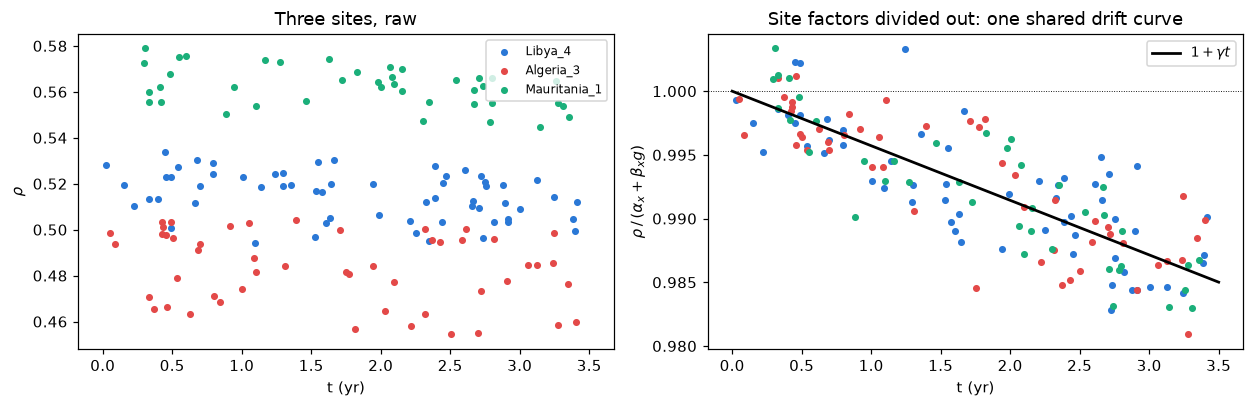

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharex=True)

for site_name in names:
    this_site_id = names.index(site_name)           
    is_this_site = site_id == this_site_id           # True/False mask: which rows belong to this site
    this_color   = site_colors[this_site_id]

    # fitted site factor, evaluated at each of its scenes' geometries
    site_factor = (alphas_fitted[this_site_id]
                               + betas_fitted[this_site_id] * g[is_this_site])

    # Left: raw observations. Right: observations divided by the site factor,
    # leaving only the shared normalized instrument response (1 + gamma*t)
    axes[0].scatter(t[is_this_site], rho[is_this_site],
                    s=13, color=this_color, label=site_name)
    axes[1].scatter(t[is_this_site], rho[is_this_site] / site_factor,
                    s=13, color=this_color)

# Overlay the fitted shared drift curve on the right panel
time_grid = np.linspace(0, 3.5, 50)
axes[1].plot(time_grid, 1 + gamma_fitted * time_grid, 'k-', lw=1.8, label=r'$1+\gamma t$')
axes[1].axhline(1, color='k', lw=0.6, ls=':')      # reference: no drift

axes[0].set_xlabel('t (yr)'); axes[1].set_xlabel('t (yr)')
axes[0].set_ylabel(r'$\rho$')
axes[1].set_ylabel(r'$\rho \,/\, (\alpha_x + \beta_x g)$')
axes[0].set_title('Three sites, raw')
axes[1].set_title('Site factors divided out: one shared drift curve')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 7. Bootstrap to quantify uncertainty in drift rate

Draw each site's scenes with replacement (preserving each site's scene count), refit the full pooled model on the resampled archive (warm start from the actual fit) and record the refitted γ. Repeat 1000 times. The standard deviation of the 1000 recorded γ values is the bootstrap SE, and the percentiles give the CI. Here I also examine fitting the model to data drawn from a single solo PICS, this will test if gamma from the 3 sites roughly agrees. Will only do this if we end up having enough data. 

In [11]:
def fit_pooled_gamma(scene_site_ids, scene_times, scene_g, scene_rho, x_start):
    """Refit the full pooled model on any set of scenes; return only gamma."""
    def misses(x):
        alphas, betas, gamma = x[:n_sites], x[n_sites:2*n_sites], x[-1]
        predicted = (alphas[scene_site_ids] + betas[scene_site_ids]*scene_g) * (1 + gamma*scene_times)
        return predicted - scene_rho
    return least_squares(misses, x_start).x[-1]

def fit_single_site_gamma(scene_times, scene_g, scene_rho):
    """Refit the 3-parameter single-site model on one site's scenes; return only gamma."""
    def misses(x):
        alpha, beta, gamma = x
        return (alpha + beta*scene_g)*(1 + gamma*scene_times) - scene_rho
    return least_squares(misses, [scene_rho.mean(), 0.0, 0.0]).x[2]

N_BOOTSTRAP = 1000
gamma_pooled_resamples = []
gamma_solo_resamples   = {site_name: [] for site_name in names}

for _ in range(N_BOOTSTRAP):

    # draw each site's scenes with replacement
    resampled_rows = []
    for site_name in names:
        this_site_id   = names.index(site_name)
        this_site_rows = np.where(site_id == this_site_id)[0]     # row numbers of this site's scenes
        drawn = rng.choice(this_site_rows, size=len(this_site_rows), replace=True)
        resampled_rows.append(drawn)
    resampled_rows = np.concatenate(resampled_rows)

    # --- refit the pooled model on the resampled archive, keep its gamma ---
    gamma_pooled_resamples.append(
        fit_pooled_gamma(site_id[resampled_rows], t[resampled_rows],
                         g[resampled_rows], rho[resampled_rows], x_fitted))

    # --- refit each site alone on its share of the resample, keep each gamma ---
    for site_name in names:
        this_site_id = names.index(site_name)
        site_rows = resampled_rows[site_id[resampled_rows] == this_site_id]
        gamma_solo_resamples[site_name].append(
            fit_single_site_gamma(t[site_rows], g[site_rows], rho[site_rows]))

print(f"{'estimate':>28} {'gamma %/yr':>11} {'boot SE':>9}")
for site_name in names:
    v = 100*np.array(gamma_solo_resamples[site_name])
    print(f"{site_name + ' alone':>28} {v.mean():>+11.3f} {v.std():>9.3f}")
v = 100*np.array(gamma_pooled_resamples)
print(f"{'POOLED (shared gamma)':>28} {v.mean():>+11.3f} {v.std():>9.3f}")
print(f"{'truth':>28} {100*GAMMA_TRUE:>+11.3f}")

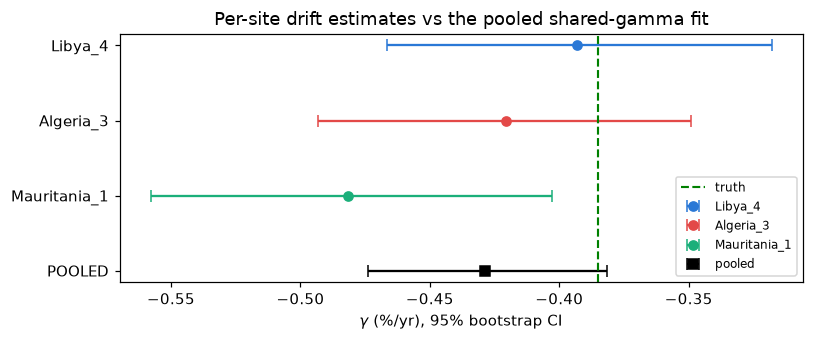

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ys = np.arange(n_sites + 1)
for i, nm in enumerate(names):
    v = 100*np.array(gamma_solo_resamples[nm])
    ci = np.percentile(v, [2.5, 97.5])
    ax.errorbar(v.mean(), i, xerr=[[v.mean()-ci[0]], [ci[1]-v.mean()]],
                fmt='o', color=site_colors[i], capsize=4, label=nm)
v = 100*np.array(gamma_pooled_resamples)
ci = np.percentile(v, [2.5, 97.5])
ax.errorbar(v.mean(), n_sites, xerr=[[v.mean()-ci[0]], [ci[1]-v.mean()]],
            fmt='s', color='k', capsize=4, ms=7, label='pooled')
ax.axvline(100*GAMMA_TRUE, color='g', ls='--', lw=1.4, label='truth')
ax.set_yticks(ys); ax.set_yticklabels(names + ['POOLED'])
ax.set_xlabel(r'$\gamma$ (%/yr), 95% bootstrap CI')
ax.set_title('Per-site drift estimates vs the pooled shared-gamma fit')
ax.legend(fontsize=8, loc='lower right')
ax.invert_yaxis()
plt.tight_layout(); plt.show()